# Boosted Decision Tree (XGBoost)
Same task, samples and rules as the logistic regression of notebook 03, now with a gradient-boosted tree ensemble that can learn non-linear combinations of the features (e.g. "both photons tight *and* isolated").

- **Signal:** ggH → γγ MC (50% train/validation, 50% test). **Background for training:** data A. **Test:** data B, C, D (9.5 fb⁻¹).
- m_γγ is not a feature; photon momenta enter only as pT/m_γγ. Section 5 shows why this matters much more for a BDT than for a linear model.
- Hyper-parameters, early stopping and the score cut are all chosen on the validation sets; data B, C, D are only used for the final numbers.

In [1]:
import sys, json, warnings
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("../src")
warnings.filterwarnings("ignore", message="Invalid or negative diphoton")

from dataset import load_all, LUMI_TEST
from features import FEATURES
from evaluate import fit_signal_shape, BINS, CENTRES, in_window
from classifier import training_set, score_all, evaluate, print_summary, save, FIG_DIR
from plotting import plot_fit

D = load_all()
for k in ["sig_train", "sig_val", "sig_test", "bkg_train", "bkg_val"]:
    print(f"{k:10s} {len(D[k]['myy']):>8d} events")
for p, d in D["data"].items():
    print(f"data {p}     {len(d['myy']):>8d} events (test)")
print(f"expected Higgs events in data B+C+D after preselection: {D['sig_test']['w'].sum():.0f}")

# Gaussian width of the Higgs peak from MC, fixed in every data fit
m0, SIGMA = fit_signal_shape(D["sig_test"]["myy"], np.abs(D["sig_test"]["w"]))
print(f"MC signal peak: mean {m0:.2f} GeV, sigma {SIGMA:.2f} GeV")

sig_train    370825 events
sig_val       92707 events
sig_test     463533 events
bkg_train     77099 events
bkg_val       19275 events
data B       341938 events (test)
data C       499912 events (test)
data D       807218 events (test)
expected Higgs events in data B+C+D after preselection: 454
MC signal peak: mean 124.99 GeV, sigma 2.34 GeV


## 1. Hyper-parameter scan
A small grid over tree depth and minimum leaf weight, learning rate 0.05, up to 3000 trees with early stopping on the validation log-loss.

In [2]:
import time
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

X_tr, y_tr, w_tr = training_set(D["sig_train"], D["bkg_train"])
X_va, y_va, w_va = training_set(D["sig_val"], D["bkg_val"])

def make_xgb(max_depth, min_child_weight):
    return XGBClassifier(
        n_estimators=3000, learning_rate=0.05, max_depth=max_depth,
        min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", eval_metric="logloss", early_stopping_rounds=50,
        n_jobs=-1, random_state=42,
    )

grid = {}
for depth in [3, 4, 6]:
    for mcw in [1, 20]:
        t = time.time()
        m = make_xgb(depth, mcw)
        m.fit(X_tr, y_tr, sample_weight=w_tr, eval_set=[(X_tr, y_tr), (X_va, y_va)],
              sample_weight_eval_set=[w_tr, w_va], verbose=False)
        ll = m.evals_result()["validation_1"]["logloss"][m.best_iteration]
        auc = roc_auc_score(y_va, m.predict_proba(X_va)[:, 1], sample_weight=w_va)
        grid[(depth, mcw)] = (ll, auc, m)
        print(f"max_depth={depth} min_child_weight={mcw:>2}: trees={m.best_iteration + 1:>4}  "
              f"val log-loss={ll:.4f}  val AUC={auc:.4f}  ({time.time() - t:.0f}s)")

best_key = min(grid, key=lambda k: grid[k][0])
xgb = grid[best_key][2]
print("chosen (max_depth, min_child_weight):", best_key)

max_depth=3 min_child_weight= 1: trees=1299  val log-loss=0.2036  val AUC=0.9668  (9s)


max_depth=3 min_child_weight=20: trees=1348  val log-loss=0.2037  val AUC=0.9667  (9s)


max_depth=4 min_child_weight= 1: trees= 738  val log-loss=0.2033  val AUC=0.9669  (6s)


max_depth=4 min_child_weight=20: trees= 786  val log-loss=0.2031  val AUC=0.9669  (6s)


max_depth=6 min_child_weight= 1: trees= 318  val log-loss=0.2029  val AUC=0.9669  (3s)


max_depth=6 min_child_weight=20: trees= 348  val log-loss=0.2029  val AUC=0.9668  (4s)
chosen (max_depth, min_child_weight): (6, 20)


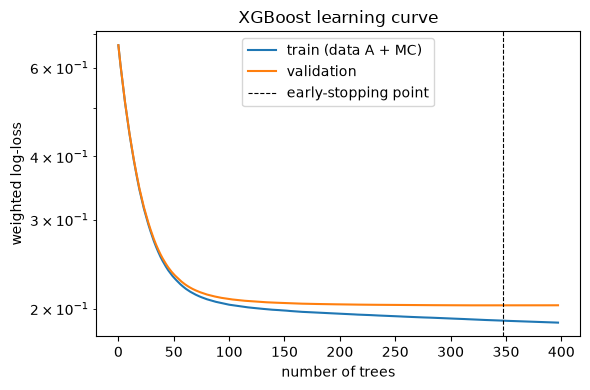

In [3]:
ev = xgb.evals_result()
plt.figure(figsize=(6, 4))
plt.plot(ev["validation_0"]["logloss"], label="train (data A + MC)")
plt.plot(ev["validation_1"]["logloss"], label="validation")
plt.axvline(xgb.best_iteration, color="k", ls="--", lw=0.8, label="early-stopping point")
plt.xlabel("number of trees"); plt.ylabel("weighted log-loss"); plt.yscale("log")
plt.legend(); plt.title("XGBoost learning curve")
plt.tight_layout(); plt.savefig(FIG_DIR / "xgb_learning_curve.png", dpi=150); plt.show()

## 2. Feature importance

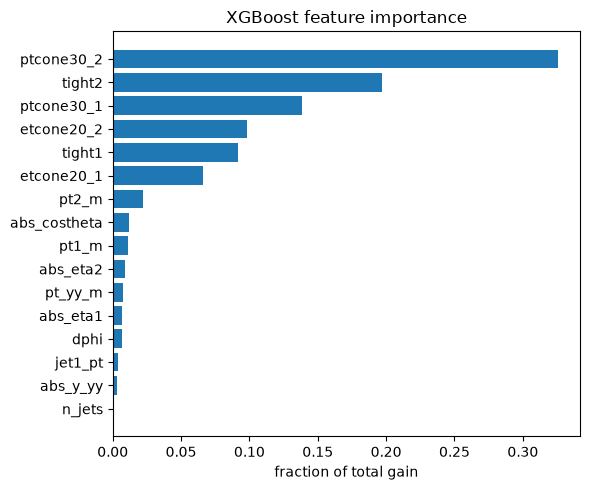

In [4]:
imp = xgb.get_booster().get_score(importance_type="total_gain")
imp = np.array([imp.get(f"f{i}", 0.0) for i in range(len(FEATURES))])
imp = imp / imp.sum()
order = np.argsort(imp)
plt.figure(figsize=(6, 5))
plt.barh(np.array(FEATURES)[order], imp[order])
plt.xlabel("fraction of total gain")
plt.title("XGBoost feature importance")
plt.tight_layout(); plt.savefig(FIG_DIR / "xgb_feature_importance.png", dpi=150); plt.show()

As for the logistic regression, photon identification and isolation dominate: the main job is rejecting jets faking photons. The kinematic variables (|cos θ*|, pT_γγ/m_γγ, ...) mostly help against the irreducible γγ continuum.

## 3. Performance on the test samples

In [5]:
def diagnostics(name, sc, res, extra):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    ax[0].plot(extra["fpr"], extra["tpr"], label=f"{name} (AUC = {res['AUC']:.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[0].plot(1 - res["bkg_rej"], res["sig_eff"], "r*", ms=12, label="chosen cut")
    ax[0].set(xscale="log", xlim=(1e-3, 1), xlabel="Background efficiency (data B+C+D)",
              ylabel="Signal efficiency (MC test)", title="ROC")
    ax[0].legend()

    bins = np.linspace(0, 1, 51)
    ax[1].hist(sc["data_bcd"], bins, density=True, histtype="step", lw=1.5, label="data B+C+D (bkg)")
    ax[1].hist(sc["sig_test"], bins, density=True, histtype="step", lw=1.5,
               weights=np.abs(D["sig_test"]["w"]), label="ggH MC (signal)")
    ax[1].axvline(res["cut"], color="r", ls="--", label="chosen cut")
    ax[1].set(yscale="log", xlabel=f"{name} score", ylabel="Normalised", title="Score distribution")
    ax[1].legend()

    scan = extra["scan"]
    ax[2].plot(scan[:, 1], scan[:, 4], "-")
    best = scan[np.argmax(scan[:, 4])]
    ax[2].plot(best[1], best[4], "r*", ms=12, label=f"best: eff = {best[1]:.2f}, Z = {best[4]:.2f}")
    ax[2].set(xlabel="Signal efficiency of score cut (validation)",
              ylabel="Expected Asimov Z (120-130 GeV)", title="Cut choice on validation set")
    ax[2].legend()
    plt.tight_layout()
    return fig


def sculpting_check(name, sc, cut):
    """Does the cut change the SHAPE of the background m_yy spectrum?
    A smooth trend is fine (the polynomial absorbs it); a bump is not."""
    d = D["data_bcd"]
    h_all, _ = np.histogram(d["myy"], BINS)
    h_cut, _ = np.histogram(d["myy"][sc["data_bcd"] >= cut], BINS)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].step(CENTRES, h_all / h_all.sum(), where="mid", label="preselection")
    ax[0].step(CENTRES, h_cut / h_cut.sum(), where="mid", label=f"{name} cut")
    ax[0].set(xlabel=r"$m_{\gamma\gamma}$ [GeV]", ylabel="Normalised", title="Data B+C+D shape")
    ax[0].legend()
    eff = h_cut / h_all
    ax[1].errorbar(CENTRES, eff, yerr=np.sqrt(eff * (1 - eff) / h_all), fmt="k.")
    ax[1].axvspan(120, 130, color="C0", alpha=0.1, label="signal window")
    ax[1].set(xlabel=r"$m_{\gamma\gamma}$ [GeV]", ylabel="Fraction of data passing cut",
              title="Cut efficiency vs mass (contains the real Higgs too)")
    ax[1].legend()
    plt.tight_layout()
    return fig

--- XGBoost ---
AUC (MC test vs data B+C+D)          0.9665
sig. eff. @ 1% / 5% bkg eff.          0.278 / 0.784
bkg. rejection @ 80% sig. eff.        0.9476
score cut (chosen on validation)      0.928
  signal efficiency / bkg rejection   0.568 / 0.9719
  data B+C+D events passing           46279
  expected Higgs events (MC)          258
  fitted Higgs events (m_H = 125)     266 ± 104
  signal strength mu                  1.03 ± 0.40
  fitted m_H                          124.56 ± 0.98 GeV
  local significance obs. / exp.      2.56 / 2.75 sigma
  corr(score, m_yy) in data           -0.0934


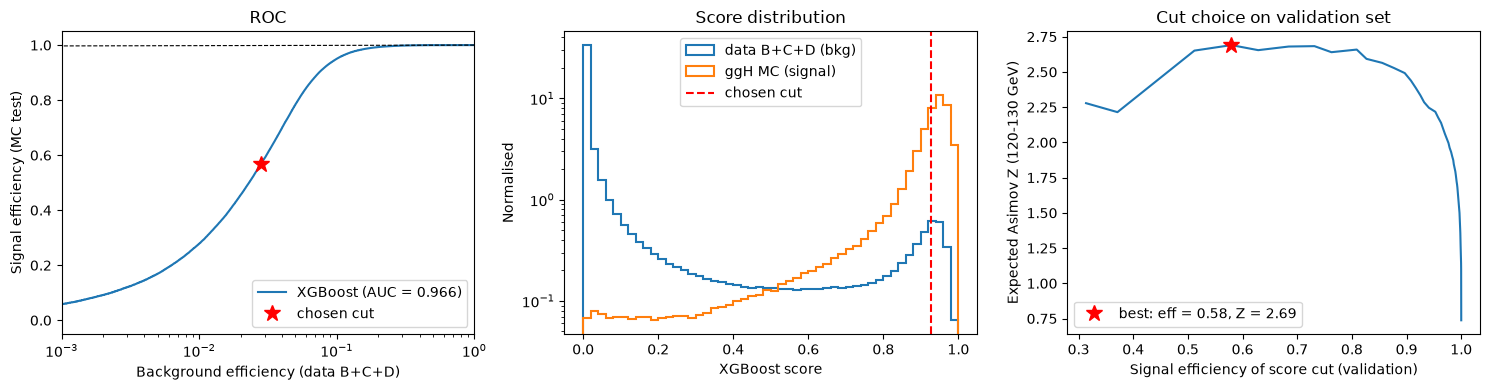

In [6]:
sc = score_all(xgb, D)
res, extra = evaluate(sc, D, SIGMA)
print_summary("XGBoost", res)

diagnostics("XGBoost", sc, res, extra)
plt.savefig(FIG_DIR / "xgb_performance.png", dpi=150)
plt.show()

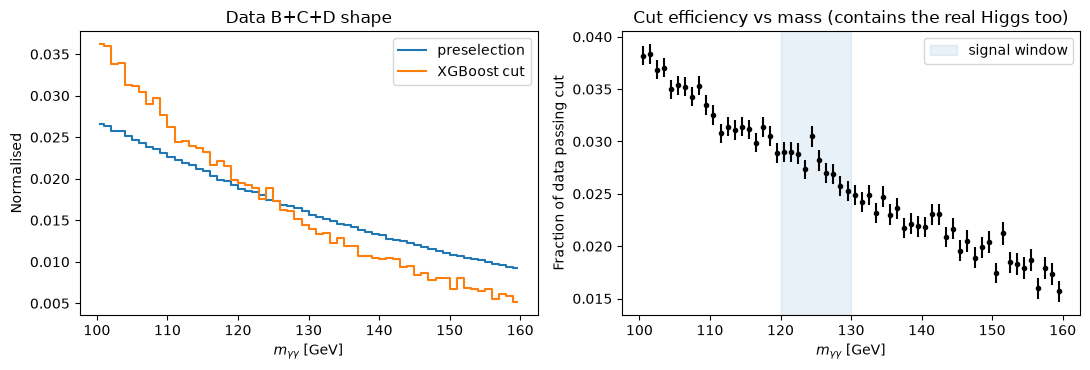

In [7]:
sculpting_check("XGBoost", sc, res["cut"])
plt.savefig(FIG_DIR / "xgb_sculpting.png", dpi=150)
plt.show()

## 4. Higgs fit in data B+C+D after the cut

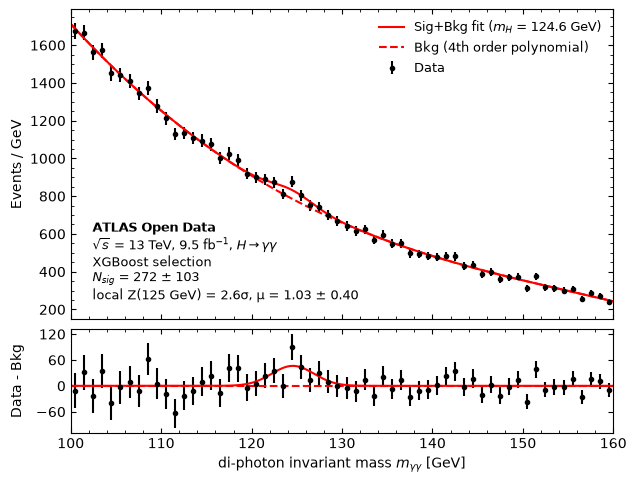

In [8]:
fig = plot_fit(extra["fit"], title="XGBoost selection", lumi=LUMI_TEST,
               label_extra=f"local Z(125 GeV) = {res['Z_obs']:.1f}σ, μ = {res['mu']:.2f} ± {res['mu_err']:.2f}")
plt.savefig(FIG_DIR / "xgb_myy_fit.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Why the photon momenta are divided by m_γγ (mass sculpting)
A tempting feature set uses the absolute photon momenta pT1, pT2, pT_γγ together with the angles. But

$$m_{\gamma\gamma}^2 = 2\,p_{T1}\,p_{T2}\,(\cosh\Delta\eta - \cos\Delta\phi)$$

and |cos θ*| = tanh(|Δη|/2), so a flexible model has everything it needs to **rebuild the mass**. Trained against a smooth background and a signal sitting at 125 GeV, it learns "m_γγ ≈ 125 GeV is signal-like" and the cut carves a peak into the *background*. Below we train exactly the same BDT with absolute momenta and look at what happens.

In [9]:
from features import FEATURES_ABS_PT

Xa_tr, _, _ = training_set(D["sig_train"], D["bkg_train"], FEATURES_ABS_PT)
Xa_va, _, _ = training_set(D["sig_val"], D["bkg_val"], FEATURES_ABS_PT)
xgb_abs = make_xgb(*best_key)
xgb_abs.fit(Xa_tr, y_tr, sample_weight=w_tr, eval_set=[(Xa_va, y_va)], sample_weight_eval_set=[w_va], verbose=False)

sc_abs = score_all(xgb_abs, D, FEATURES_ABS_PT)
res_abs, extra_abs = evaluate(sc_abs, D, SIGMA)
print_summary("XGBoost with absolute pT (DO NOT USE)", res_abs)

--- XGBoost with absolute pT (DO NOT USE) ---
AUC (MC test vs data B+C+D)          0.9880
sig. eff. @ 1% / 5% bkg eff.          0.639 / 0.968
bkg. rejection @ 80% sig. eff.        0.9832
score cut (chosen on validation)      0.961
  signal efficiency / bkg rejection   0.697 / 0.9880
  data B+C+D events passing           19784
  expected Higgs events (MC)          316
  fitted Higgs events (m_H = 125)     10037 ± 123
  signal strength mu                  31.72 ± 0.39
  fitted m_H                          124.89 ± 0.04 GeV
  local significance obs. / exp.      93.84 / 5.47 sigma
  corr(score, m_yy) in data           -0.0002


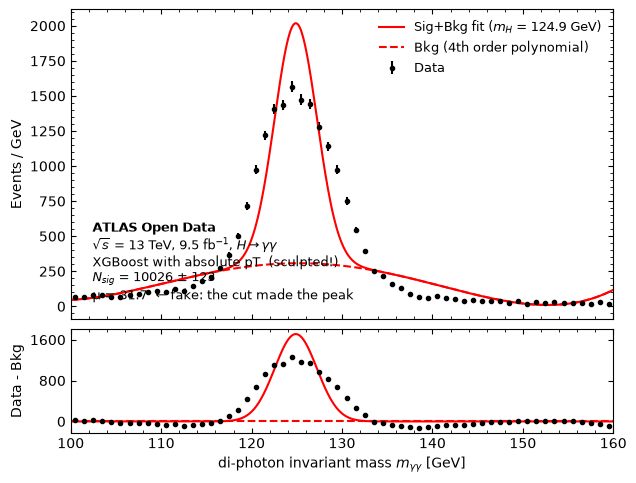

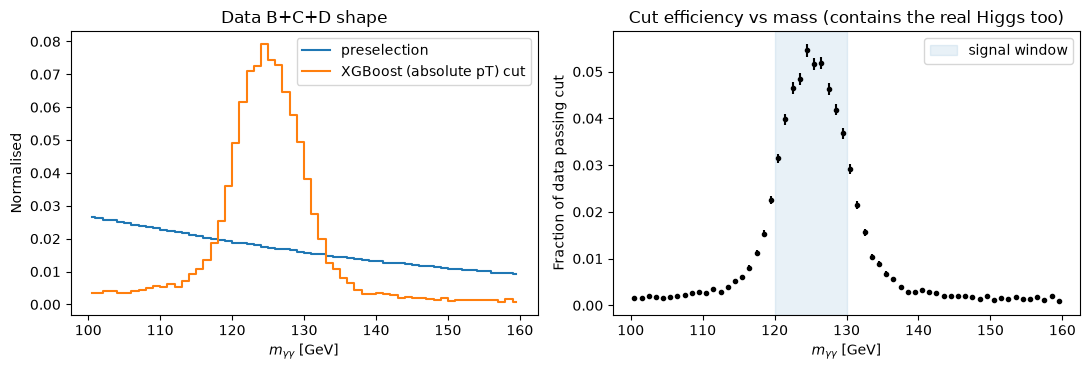

In [10]:
fig = plot_fit(extra_abs["fit"], title="XGBoost with absolute pT  (sculpted!)", lumi=LUMI_TEST,
               label_extra=f"μ = {res_abs['mu']:.1f}  ← fake: the cut made the peak")
plt.savefig(FIG_DIR / "xgb_abs_pt_sculpting_fit.png", dpi=150, bbox_inches="tight")
plt.show()
sculpting_check("XGBoost (absolute pT)", sc_abs, res_abs["cut"])
plt.savefig(FIG_DIR / "xgb_abs_pt_sculpting.png", dpi=150)
plt.show()

The absolute-pT model has a higher AUC, but its cut efficiency in data is sharply peaked at 125 GeV and the fitted "signal" is many times the Standard Model expectation. That peak is made by the selection, not by a Higgs boson. With pT/m_γγ the efficiency versus mass is smooth (section 3), the 4th-order polynomial still describes the background, and the fitted signal agrees with the expectation.

## 6. Save

In [11]:
from pathlib import Path
model_dir = Path("../results/models"); model_dir.mkdir(parents=True, exist_ok=True)
xgb.save_model(model_dir / "xgboost.json")
res["hyperparameters"] = {"max_depth": best_key[0], "min_child_weight": best_key[1],
                          "learning_rate": 0.05, "n_trees": int(xgb.best_iteration + 1)}
save("xgboost", sc, res)
res_abs.pop("hyperparameters", None)
save("xgboost_abs_pt", sc_abs, res_abs)
print("saved model, scores and summaries")

saved model, scores and summaries


## Notes
- The significance is local at m_H = 125 GeV, statistical only (no systematics, no look-elsewhere effect).
- Data A is used as training background and contains ~50 real Higgs events that the BDT was told are background. That is why data A is excluded from every fit: on A itself the classifier is biased against the signal.
- Side-by-side comparison with the tutorial cuts and the logistic regression: `05_global_comparison.ipynb`.